<div style="display:flex; align-items:center; gap:18px; text-align:left">

<div>
<p>Ingeniería en Información y Control de Gestión</p>
<p>Facultad de Economía y Negocios</p>
<p>Introducción a Machine Learning</p>
<p>Proyecto capstone: ejemplo resuelto de clasificación</p>
</div>
</div>

# Ejemplo resuelto · clasificación

Este notebook recorre los 16 pasos de la [plantilla del capstone](https://colab.research.google.com/github/sebastiancontz/ust-introduccion-machine-learning-colab/blob/main/ediciones/2026/notebooks/capstone-plantilla.ipynb) con `riesgo_impago.csv`, el
archivo de las sesiones 7 a 12. Sirve para ver **cómo se ve cada paso resuelto**: qué código lleva, qué se
anota y qué sale para la presentación.

Es una guía, no un molde: su caso tiene otros datos, otra decisión y otros problemas, y sus decisiones
pueden ser distintas de las de acá. Lo que se copia es el **orden y el rigor**, no las cifras.

## Paso 0 · Librerías

In [1]:
%%capture
!pip install -q pandas numpy pyarrow matplotlib seaborn scikit-learn shap joblib

In [2]:
import os                          # revisa si los datos están en una carpeta local
import time                        # mide cuánto tarda cada modelo
import numpy as np                 # cálculo numérico
import pandas as pd                # tablas
import matplotlib.pyplot as plt    # gráficos
import seaborn as sns              # gráficos estadísticos
import shap                        # explicaciones del modelo
import joblib                      # guarda y carga el modelo
import sklearn                     # para anotar su versión

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
                              HistGradientBoostingClassifier, HistGradientBoostingRegressor)
from sklearn.metrics import (roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, mean_absolute_error, silhouette_score)
from sklearn.cluster import KMeans

## Paso 1 · El canvas, antes de programar

- **Decisión que apoya el modelo y quién la toma:** el área de cobranza decide cada mes a qué clientes
  llamar primero, antes de que venza el pago.
- **Qué es un registro:** un cliente de tarjeta de crédito observado en un mes.
- **Qué se predice y con qué horizonte; clasificación o regresión:** `incumplio_pago`, si el cliente
  incumple el pago **del mes siguiente** (sí o no). Es clasificación: el target es una categoría.
- **Momento de la predicción:** al cierre del mes observado. Se conocen la mora, lo facturado y lo
  pagado de ese mes y de los anteriores; no se sabe si pagará el mes siguiente.
- **Columnas que excluyen y por qué:** `id_cliente`, porque es un identificador reasignado y no describe
  al cliente.
- **Métrica y criterio de éxito:** el **costo en llamadas** de la lista con su umbral, contra el
  baseline que no llama a nadie. El ROC-AUC acompaña, porque mide si el modelo ordena bien.
- **En clasificación, cuánto cuesta cada error:** un impago que se escapa vale lo mismo que **5 llamadas
  de más** (la razón de las sesiones 11 y 12).

In [3]:
SEMILLA = 42   # la misma en la muestra, la partición y cada modelo que sortea

ARCHIVO = 'riesgo_impago.csv'
TARGET = 'incumplio_pago'
EXCLUIDAS = ['id_cliente']   # identificador: no describe al cliente
RAZON = 5                    # un impago que se escapa vale 5 llamadas de más

> **Para la presentación:** sección 1 del enunciado: el canvas completo y coherente.

## Paso 2 · Cargar los datos

In [4]:
REPO = 'https://raw.githubusercontent.com/sebastiancontz/ust-introduccion-machine-learning-colab/main/ediciones/2026/datasets/'
BASE = '../datasets/' if os.path.exists('../datasets') else REPO  # en Colab siempre se usa REPO

datos = pd.read_csv(BASE + ARCHIVO)
print('registros y columnas:', datos.shape)
datos.head()

registros y columnas: (6000, 16)


,id_cliente,edad,nivel_educacion,limite_credito,meses_mora,meses_mora_previo,meses_mora_acumulados,monto_facturado_mes,monto_facturado_mes_anterior,monto_facturado_dos_meses_antes,monto_pagado_mes,monto_pagado_mes_anterior,monto_pagado_dos_meses_antes,uso_credito,cobertura_pago,incumplio_pago
0,R-0001,34,universitaria,90000,0,0,0,29239,14027,13559,1518,1500,1000,0.3249,0.0519,no
1,R-0002,37,posgrado,50000,0,0,0,64400,57069,57608,2500,1815,657,1.2880,0.0388,no
2,R-0003,29,posgrado,250000,0,0,0,70887,67060,63561,3000,3000,3000,0.2835,0.0423,no
3,R-0004,26,universitaria,70000,2,0,6,41087,42445,45020,2007,3582,0,0.5870,0.0488,si
4,R-0005,47,media,50000,0,0,0,650,3415,3416,3415,3421,2044,0.0130,3.0000,no


## Paso 3 · La calidad de los datos

In [5]:
datos.info()   # tipos y valores no vacíos

<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 16 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   id_cliente                       6000 non-null   str    
 1   edad                             6000 non-null   int64  
 2   nivel_educacion                  6000 non-null   str    
 3   limite_credito                   6000 non-null   int64  
 4   meses_mora                       6000 non-null   int64  
 5   meses_mora_previo                6000 non-null   int64  
 6   meses_mora_acumulados            6000 non-null   int64  
 7   monto_facturado_mes              6000 non-null   int64  
 8   monto_facturado_mes_anterior     6000 non-null   int64  
 9   monto_facturado_dos_meses_antes  6000 non-null   int64  
 10  monto_pagado_mes                 6000 non-null   int64  
 11  monto_pagado_mes_anterior        6000 non-null   int64  
 12  monto_pagado_dos_meses_antes   

In [6]:
print('vacíos en todo el archivo:', datos.isna().sum().sum())
print('filas idénticas a otra:', datos.duplicated().sum())

vacíos en todo el archivo: 0
filas idénticas a otra: 0


In [7]:
datos.describe().T.round(2)   # rangos de las numéricas

,count,mean,std,min,25%,50%,75%,max
edad,6000.0,35.52,9.20,21.00,28.00,34.00,41.00,75.00
limite_credito,6000.0,165745.61,128812.18,10000.00,50000.00,140000.00,230000.00,750000.00
meses_mora,6000.0,0.35,0.74,0.00,0.00,0.00,0.00,8.00
meses_mora_previo,6000.0,0.32,0.79,0.00,0.00,0.00,0.00,7.00
meses_mora_acumulados,6000.0,1.34,3.10,0.00,0.00,0.00,2.00,34.00
monto_facturado_mes,6000.0,50132.31,72428.80,-165580.00,3605.00,21904.00,65114.75,653062.00
monto_facturado_mes_anterior,6000.0,48116.56,69751.32,-24702.00,3043.25,20613.00,62696.25,671563.00
monto_facturado_dos_meses_antes,6000.0,46168.62,68062.20,-157264.00,2878.50,19903.50,59176.75,693131.00
monto_pagado_mes,6000.0,5881.03,19774.72,0.00,1000.00,2151.50,5011.25,873552.00
monto_pagado_mes_anterior,6000.0,6035.03,23432.67,0.00,919.75,2027.00,5000.00,1215471.00


In [8]:
datos[TARGET].value_counts(normalize=True).round(3)   # reparto del target

incumplio_pago
no    0.772
si    0.228
Name: proportion, dtype: float64

**Problemas encontrados y cuántos registros afecta cada uno:**

- No hay vacíos ni filas repetidas.
- `monto_facturado_mes` y los otros dos montos facturados tienen **mínimos negativos**. No es un error:
  el diccionario dice que es un saldo a favor del cliente. Se dejan como están.
- `uso_credito` (lo facturado dividido por el cupo) baja de 0 por esos saldos y supera 1 cuando lo
  facturado excede el cupo. También se deja: es información del cliente, no un error de carga.
- El target está desbalanceado: alrededor de **uno de cada cinco** clientes incumple. Por eso la
  partición se estratifica y la exactitud no sirve como métrica.

> **Para la presentación:** sección 2: registros, columnas y tipos; los problemas de calidad, con cifras.

## Paso 4 · Exploración: 2 o 3 gráficos relevantes

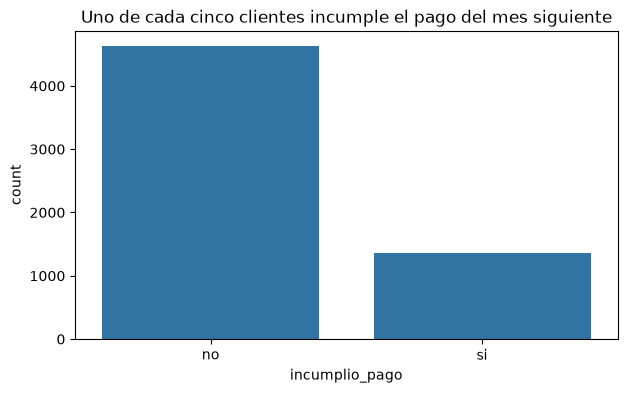

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=datos, x=TARGET, ax=ax)
ax.set_title('Uno de cada cinco clientes incumple el pago del mes siguiente')
plt.show()

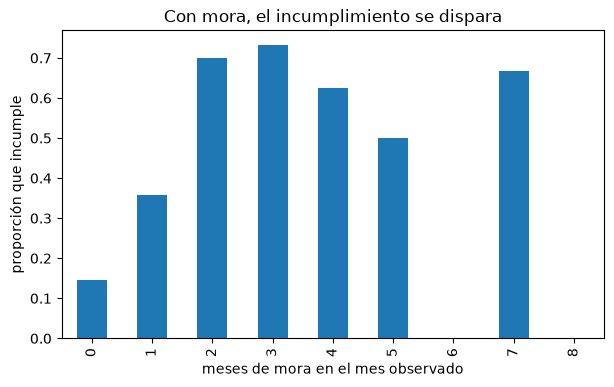

In [10]:
incumple = datos[TARGET] == 'si'
tasa_por_mora = incumple.groupby(datos['meses_mora']).mean()   # proporción de incumplimiento por nivel de mora

fig, ax = plt.subplots(figsize=(7, 4))
tasa_por_mora.plot.bar(ax=ax)
ax.set_xlabel('meses de mora en el mes observado')
ax.set_ylabel('proporción que incumple')
ax.set_title('Con mora, el incumplimiento se dispara')
plt.show()

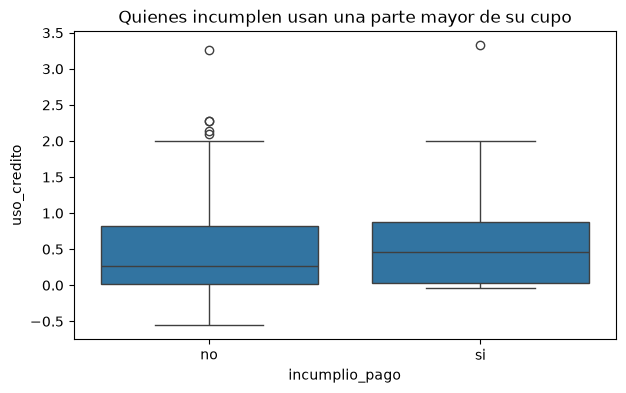

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=datos, x=TARGET, y='uso_credito', ax=ax)
ax.set_title('Quienes incumplen usan una parte mayor de su cupo')
plt.show()

**Lectura de cada gráfico** (qué muestra y qué decisión informa):

1. El reparto del target: la clase positiva es minoritaria. **Informa** la partición estratificada y la
   métrica de costo en vez de la exactitud: un modelo que dice «siempre no» acertaría a casi el 80 %.
2. La proporción de incumplimiento por meses de mora: pasa de 15 % sin mora a 36 % con un mes y a 70 %
   con dos. Sobre 3 meses hay muy pocos clientes (28 en total) y las barras saltan por azar: no se leen.
   **Informa** que la mora será la señal principal y que conviene probar árboles, que capturan saltos.
3. El uso del cupo según el target: la mediana de quienes incumplen es más alta. **Informa** que
   `uso_credito` aporta, aunque las cajas se solapan: ninguna variable sola separa a los grupos.

> **Para la presentación:** sección 2: cada gráfico con lo que muestra y qué decisión informa.

## Paso 5 · Preparación sin fuga

No hay filas que quitar ni muestra que tomar: el archivo tiene 6.000 registros sin repetidas. La única
categórica es `nivel_educacion`; las demás columnas, salvo el identificador y el target, son numéricas.

In [12]:
y = (datos[TARGET] == 'si').astype(int)   # 1 = incumple, la clase positiva
X = datos.drop(columns=[TARGET] + EXCLUIDAS)

COLUMNAS_NUM = list(X.select_dtypes(include='number').columns)
COLUMNAS_CAT = list(X.select_dtypes(exclude='number').columns)
print('numéricas:', COLUMNAS_NUM)
print('categóricas:', COLUMNAS_CAT)

numéricas: ['edad', 'limite_credito', 'meses_mora', 'meses_mora_previo', 'meses_mora_acumulados', 'monto_facturado_mes', 'monto_facturado_mes_anterior', 'monto_facturado_dos_meses_antes', 'monto_pagado_mes', 'monto_pagado_mes_anterior', 'monto_pagado_dos_meses_antes', 'uso_credito', 'cobertura_pago']
categóricas: ['nivel_educacion']


In [13]:
ruta_numerica = Pipeline([
    ('rellenar', SimpleImputer(strategy='median')),   # la mediana de entrenamiento rellena los vacíos
    ('escalar', StandardScaler()),                    # promedio 0 y desviación 1
])
preparar = ColumnTransformer([
    ('num', ruta_numerica, COLUMNAS_NUM),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), COLUMNAS_CAT),
], verbose_feature_names_out=False).set_output(transform='pandas')   # una tabla con nombres, para SHAP

**Decisiones de preparación y su motivo:**

- Se excluye `id_cliente`: no describe al cliente.
- Los vacíos se rellenan con la mediana de entrenamiento. Hoy no hay ninguno, pero el pipeline queda
  listo si un mes llegan.
- Las numéricas se escalan, porque la regresión logística lo necesita; a los árboles no les afecta.
- `nivel_educacion` pasa por *one-hot*; una categoría que no aparezca en entrenamiento se ignora.

> **Para la presentación:** secciones 1 y 2: qué columnas excluyeron y por qué; las decisiones de
> preparación.

## Paso 6 · La partición: entrenamiento, validación y prueba

Cada registro es un cliente distinto y la decisión no depende del orden en el tiempo, así que la
partición es **al azar**, 60/20/20. Como es clasificación, se estratifica.

In [14]:
# primero se aparta la prueba (20 %); lo que queda son entrenamiento y validación todavía juntos
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEMILLA, stratify=y)

# ese bloque se parte: el 25 % del 80 % que quedó es el 20 % del archivo
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, random_state=SEMILLA, stratify=y_trainval)

print('entrenamiento:', len(X_train), '· validación:', len(X_val), '· prueba:', len(X_test))
print('proporción que incumple en cada parte:',
      round(y_train.mean(), 3), round(y_val.mean(), 3), round(y_test.mean(), 3))

entrenamiento: 3600 · validación: 1200 · prueba: 1200
proporción que incumple en cada parte: 0.228 0.228 0.228


**Cómo partimos y por qué:** al azar y estratificado, 60/20/20, con semilla 42. Las tres partes quedan
con la misma proporción de incumplimiento.

> **Para la presentación:** sección 3: cómo partieron los datos y por qué respeta la estructura de su
> caso.

## Paso 7 · El baseline y los candidatos

El baseline predice siempre la clase más frecuente, «no incumple»: no llama a nadie. Los tres
candidatos son los de la sesión 12.

In [15]:
candidatos = {
    'Baseline': DummyClassifier(strategy='most_frequent'),
    'Regresión logística': LogisticRegression(max_iter=2000),
    'Árbol de decisión': DecisionTreeClassifier(max_depth=5, random_state=SEMILLA),
    'Random forest': RandomForestClassifier(min_samples_leaf=20, random_state=SEMILLA),
}

## Paso 8 · La comparación, en validación

Para cada candidato y cada umbral de la grilla se cuentan los impagos que se escapan y las falsas
alarmas, y se calcula el costo: 5 × escapados + falsas alarmas. La tabla guarda el umbral más barato de
cada modelo.

In [16]:
GRILLA = np.round(np.arange(0.05, 0.91, 0.05), 2)   # umbrales de 0,05 a 0,90

def costo_por_umbral(prob, y_real):
    # una fila por umbral: impagos que se escapan, falsas alarmas y costo
    filas = []
    for umbral in GRILLA:
        llamar = np.where(prob >= umbral, 1, 0)
        _, falsas, escapados, _ = confusion_matrix(y_real, llamar, labels=[0, 1]).ravel()
        filas.append({'umbral': umbral, 'escapados': escapados, 'falsas_alarmas': falsas,
                      'costo': RAZON * escapados + falsas})
    return pd.DataFrame(filas)

In [17]:
filas = []
modelos = {}
for nombre, estimador in candidatos.items():
    inicio = time.time()
    modelo = Pipeline([('preparar', clone(preparar)), ('modelo', clone(estimador))])
    modelo.fit(X_train, y_train)   # el único ajuste, y solo con entrenamiento
    prob_val = modelo.predict_proba(X_val)[:, 1]
    costos = costo_por_umbral(prob_val, y_val)
    mejor = costos.loc[costos['costo'].idxmin()]
    filas.append({'modelo': nombre,
                  'segundos': round(time.time() - inicio, 1),
                  'roc_auc_train': roc_auc_score(y_train, modelo.predict_proba(X_train)[:, 1]),
                  'roc_auc_val': roc_auc_score(y_val, prob_val),
                  'umbral': mejor['umbral'],
                  'costo_val': mejor['costo']})
    modelos[nombre] = modelo   # se guarda para no reentrenar al elegido

tabla = pd.DataFrame(filas).round(3)
tabla

,modelo,segundos,roc_auc_train,roc_auc_val,umbral,costo_val
0,Baseline,0.0,0.500,0.500,0.05,1365.0
1,Regresión logística,0.0,0.766,0.738,0.15,736.0
2,Árbol de decisión,0.0,0.781,0.748,0.10,683.0
3,Random forest,0.3,0.881,0.771,0.15,701.0


**Lectura de la tabla:** los tres modelos cuestan cerca de la mitad que el baseline. El árbol tiene el
menor costo (683 llamadas) y el bosque, el mejor ROC-AUC (0,771). El bosque ordena mucho mejor en
entrenamiento que en validación (0,881 contra 0,771): aprendió algo de memoria, aunque igual es el que
mejor ordena a clientes que no vio.

> **Para la presentación:** sección 3: las métricas de todos los modelos en una misma tabla.

## Paso 9 · (opcional) ¿La diferencia es real o es suerte de la partición?

Entre el árbol y el bosque hay 18 llamadas de costo, sobre 1.200 clientes: una sola partición no dice
si es real. Cinco pliegues estratificados de `X_trainval` miden cuánto ordena cada uno y cuánto varía.

In [18]:
pliegues = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
for nombre in ['Árbol de decisión', 'Random forest']:
    puntajes = cross_val_score(modelos[nombre], X_trainval, y_trainval, cv=pliegues, scoring='roc_auc')
    print(f'{nombre}: ROC-AUC media {puntajes.mean():.3f} · desviación {puntajes.std():.3f}')

Árbol de decisión: ROC-AUC media 0.736 · desviación 0.011


Random forest: ROC-AUC media 0.776 · desviación 0.015


## Paso 10 · La elección, antes de abrir la prueba

In [19]:
elegido = modelos['Random forest']
costos = costo_por_umbral(elegido.predict_proba(X_val)[:, 1], y_val)
UMBRAL = costos.loc[costos['costo'].idxmin(), 'umbral']   # el de menor costo en validación
print('umbral elegido:', UMBRAL)
costos

umbral elegido: 0.15


,umbral,escapados,falsas_alarmas,costo
0,0.05,2,829,839
1,0.10,18,662,752
2,0.15,50,451,701
3,0.20,89,260,705
4,0.25,117,173,758
5,0.30,134,120,790
6,0.35,145,94,819
7,0.40,156,81,861
8,0.45,168,68,908
9,0.50,186,54,984


**Elegimos** el random forest, aunque el árbol cuesta 18 llamadas menos en validación, **porque** en la
validación cruzada el bosque ordena mejor (ROC-AUC 0,776 contra 0,736) y esa diferencia es mayor que la
variación entre pliegues (0,015 y 0,011). Las 18 llamadas, en cambio, pueden ser suerte de una partición.
El árbol también habría sido defendible, por simple: lo que no vale es elegir sin motivo.

**Umbral:** el de menor costo en validación **porque** con la razón 5 a 1 conviene llamar de más antes
que dejar escapar impagos: el umbral queda muy por debajo de 0,5.

> **Para la presentación:** sección 3: cuál eligieron y por qué; en clasificación, también con qué
> umbral.

## Paso 11 · El cierre con prueba, una sola vez

ROC-AUC en prueba: 0.748
con el modelo · escapados: 61 · falsas alarmas: 439 · costo: 744
baseline      · escapados: 273 · falsas alarmas: 0 · costo: 1365


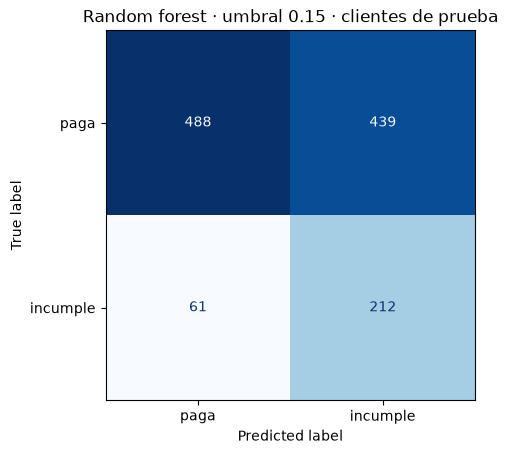

In [20]:
prob_test = elegido.predict_proba(X_test)[:, 1]   # la prueba se abre acá, y solo acá
costos_test = costo_por_umbral(prob_test, y_test)
final = costos_test.loc[costos_test['umbral'] == UMBRAL].iloc[0]
costo_baseline = RAZON * y_test.sum()   # el baseline no llama a nadie: se le escapan todos

print('ROC-AUC en prueba:', round(roc_auc_score(y_test, prob_test), 3))
print('con el modelo · escapados:', int(final['escapados']), '· falsas alarmas:',
      int(final['falsas_alarmas']), '· costo:', int(final['costo']))
print('baseline      · escapados:', y_test.sum(), '· falsas alarmas: 0 · costo:', costo_baseline)

ConfusionMatrixDisplay.from_predictions(y_test, np.where(prob_test >= UMBRAL, 1, 0),
                                        display_labels=['paga', 'incumple'], cmap='Blues', colorbar=False)
plt.title(f'Random forest · umbral {UMBRAL} · clientes de prueba')
plt.show()

> **Para la presentación:** secciones 3 y 5: el resultado final, frente al baseline y al criterio de
> éxito.

## Paso 12 · Interpretación con SHAP

In [21]:
casos = X_test.sample(n=200, random_state=SEMILLA)                 # 200 clientes de prueba
casos_prep = elegido.named_steps['preparar'].transform(casos)      # ya preparados, con nombres
explicador = shap.TreeExplainer(elegido.named_steps['modelo'])     # el bosque, no el pipeline
explicacion = explicador(casos_prep)[:, :, 1]                      # la clase «incumple»

# para los gráficos: las numéricas en sus unidades, no estandarizadas (los aportes no cambian)
originales = casos_prep.copy()
originales[COLUMNAS_NUM] = casos[COLUMNAS_NUM]
explicacion.data = originales.to_numpy()

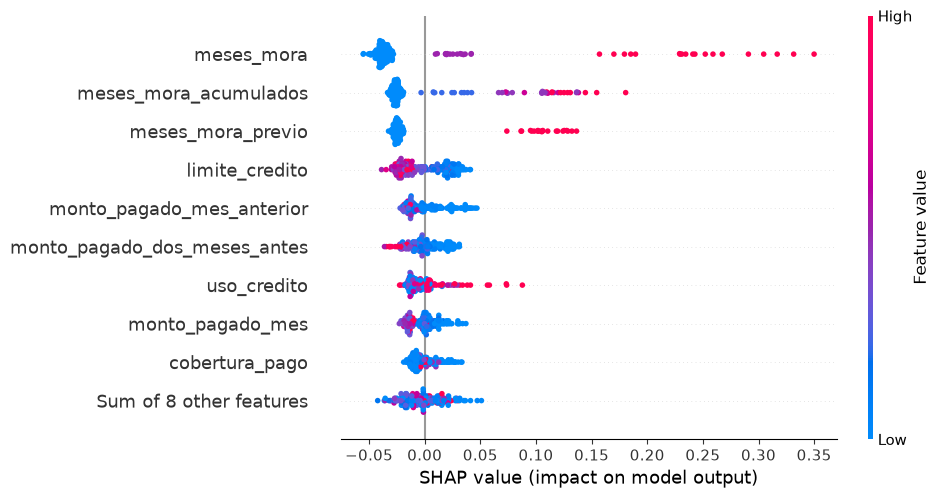

In [22]:
shap.plots.beeswarm(explicacion)   # global

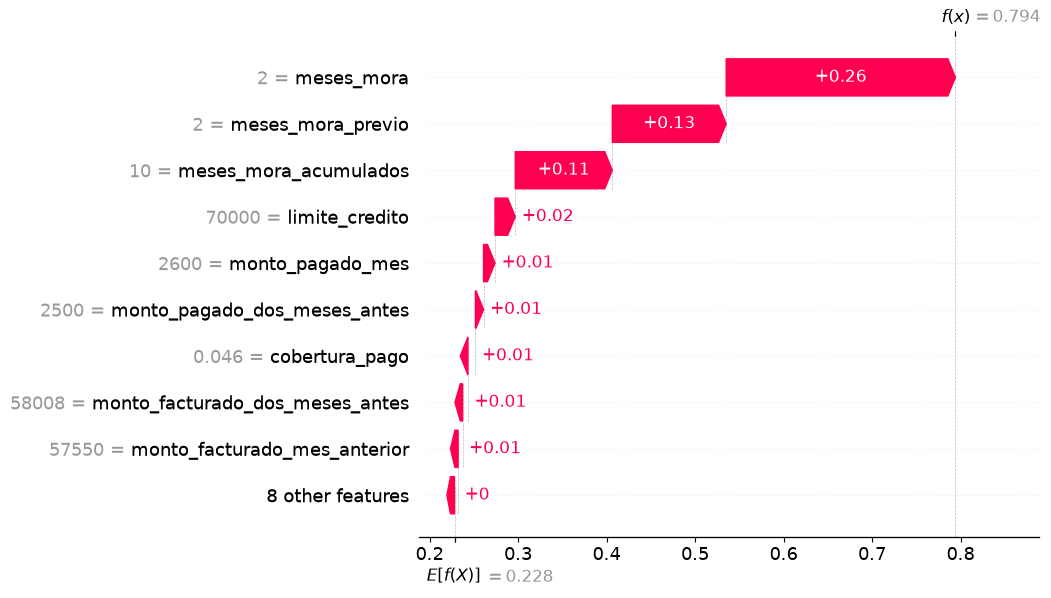

In [23]:
prob_casos = elegido.predict_proba(casos)[:, 1]
mas_riesgoso = int(np.argmax(prob_casos))   # el cliente con mayor probabilidad de incumplir
shap.plots.waterfall(explicacion[mas_riesgoso])

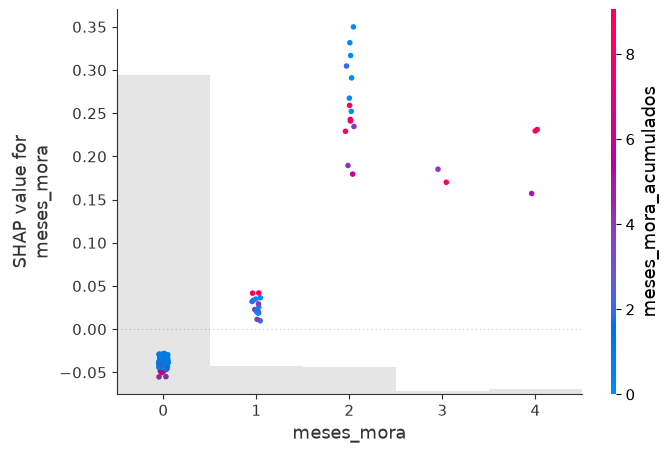

In [24]:
shap.plots.scatter(explicacion[:, 'meses_mora'], color=explicacion)   # dependencia de la mora

**Qué permiten afirmar estas explicaciones y qué no:**

- Permiten afirmar que, **para este modelo**, la mora del mes es la variable que más mueve la
  probabilidad de incumplir, seguida de la mora acumulada y la del mes anterior, y que su aporte crece
  al pasar de 0 a 1 mes y, sobre todo, a 2.
- Permiten explicar a cobranza por qué un cliente concreto quedó arriba en la lista.
- **No** permiten afirmar que reducir la mora de un cliente reduciría su riesgo: SHAP describe
  asociaciones que el modelo aprendió, no causas.

> **Para la presentación:** sección 4: la explicación global, la de un caso y la de dependencia,
> leídas como asociación.

## Paso 13 · De la cifra a la recomendación

| Pregunta | Respuesta del equipo |
|:--|:--|
| ¿Cuánto mejora el modelo frente al baseline, en la unidad de la decisión? | En prueba, el costo baja de 1.365 a 744 llamadas, un 45 % menos |
| ¿Se cumplió el criterio de éxito del canvas? ¿Qué cambió respecto de lo planificado y por qué? | Sí: el costo es menor que el del baseline. No cambió el plan |
| ¿Qué gana la organización al usar el modelo frente a no usarlo? | Detecta 212 de los 273 impagos de prueba (78 %) llamando a 651 de 1.200 clientes, en vez de no llamar a nadie o llamar a todos. Es una lista larga: si cobranza no tiene capacidad para tantas llamadas, la razón 5 a 1 hay que revisarla |
| ¿Qué riesgos y límites tiene? | Datos de 2005 y de otro país; la razón 5 a 1 es un supuesto de cobranza que conviene revisar; el modelo no sabe por qué un cliente deja de pagar |
| Si el modelo se usara, ¿qué habría que observar? | Cada mes, cuántos de los llamados incumplen y cuántos impagos no estaban en la lista; si cambian, revisar el umbral |

> **Para la presentación:** sección 5.

## Paso 14 · (opcional) Segmentación con K-means

No la hicimos en este ejemplo: el de regresión la muestra paso a paso.

## Paso 15 · (opcional) Exportar el modelo y los resultados

En clasificación, el umbral no queda dentro del pipeline: se anota aparte.

In [25]:
joblib.dump(elegido, 'riesgo_bosque.joblib')        # guarda el pipeline ajustado
cargado = joblib.load('riesgo_bosque.joblib')       # lo recupera, sin reentrenar
print('mismas predicciones tras guardar y cargar:',
      np.array_equal(elegido.predict(X_val), cargado.predict(X_val)))

print('pandas', pd.__version__, '· numpy', np.__version__, '· scikit-learn', sklearn.__version__)
print('shap', shap.__version__, '· joblib', joblib.__version__)

print('umbral, para anotar junto al archivo:', UMBRAL)

mismas predicciones tras guardar y cargar: True
pandas 3.0.5 · numpy 2.4.6 · scikit-learn 1.9.0
shap 0.51.0 · joblib 1.5.3
umbral, para anotar junto al archivo: 0.15


## Antes de llevar cifras a la presentación

- [x] **Entorno de ejecución → Reiniciar sesión y ejecutar todo**: este notebook corre de arriba abajo.
- [x] Las cifras de este notebook son las de esa corrida.
- [x] La semilla (42) y las versiones de las librerías están anotadas; no se usó muestra.
- [x] La prueba se abrió una sola vez, después de elegir modelo y umbral.
- [x] Cada decisión tiene su motivo escrito en el paso que corresponde.

## Atribución de datos

- **Creador:** Yeh, I. C., & Lien, C. H. (2009)
- **Fuente:** [UCI Machine Learning Repository — *Default of Credit Card Clients*, dataset 350](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients)
- **Licencia:** [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/)
- **Modificación:** obra derivada. Se tomaron 6.000 registros y 16 columnas del original de 30.000 ×
  25, con los nombres traducidos al español en `snake_case`, la escolaridad recodificada a etiquetas y
  dos razones derivadas nuevas. Los atributos sexo y estado civil se excluyeron deliberadamente.